# 20장 · 분배함수 — 예제 풀이

**열및통계물리2 · 교재 20장 분배함수 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

교재 20장의 예제 20.1–20.5와 추가 문제(연습문제 20.8)를 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다.
에너지는 준위 간격 $\Delta$(또는 $\hbar\omega$) 단위, 온도는 $t=k_BT/\Delta$로 쓰는 곳이 많다(무차원). 그래프 라벨은 영어로 쓴다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 공통 도구 — 준위 목록에서 열역학량 계산

분배함수 $Z=\sum_\alpha e^{-\beta E_\alpha}$ (교재 식 20.1)에서 $U=-\partial\ln Z/\partial\beta$ (20.9), $S=k_B(\ln Z+\beta U)$ (20.12), $C_V=(\partial U/\partial T)_V$ (20.18)를 구한다.
$C_V$는 $\beta^2\langle(\Delta E)^2\rangle$로 계산하고, 수치미분과도 맞춰 본다. 수치 안정성을 위해 바닥 에너지를 빼고 더한다.

In [2]:
def thermo(E, g, t):
    """준위 E (Delta 단위), 축퇴도 g, 온도 t = k_BT/Delta → (lnZ, U/Delta, S/k_B, C/k_B)"""
    E, g = np.asarray(E, float), np.asarray(g, float)
    b = 1.0 / t
    w = g * np.exp(-b * (E - E.min()))
    Zs = w.sum(); P = w / Zs
    U = (P * E).sum()
    var = (P * (E - U) ** 2).sum()
    lnZ = -b * E.min() + np.log(Zs)
    return lnZ, U, lnZ + b * U, b * b * var

def levels(system, t, N=20):
    """교재 예제 20.1, 20.2의 네 가지 계 (에너지는 Delta 단위)"""
    if system == 'two':                       # ±Delta/2
        return [-0.5, 0.5], [1, 1]
    if system == 'sho':                       # (n+1/2) hbar*omega, Delta = hbar*omega
        n = np.arange(0, int(60 * t) + 20); return n + 0.5, np.ones_like(n)
    if system == 'nlev':                      # j*hbar*omega, j = 0..N-1
        j = np.arange(N); return j, np.ones_like(j)
    if system == 'rot':                       # Delta J(J+1), g = 2J+1, Delta = hbar^2/2I
        J = np.arange(0, int(np.sqrt(60 * t)) + 20); return J * (J + 1), 2 * J + 1
print('helpers ready')

helpers ready


## 예제 20.1, 20.2 — 네 가지 계의 분배함수 (교재 284–286쪽)

**문제 요약.** (a) 에너지 $\pm\Delta/2$인 2준위계, (b) 조화진동자 $E_n=(n+\tfrac12)\hbar\omega$, (c) 준위 $0,\hbar\omega,\dots,(N-1)\hbar\omega$인 N준위계, (d) 회전자 $E_J=\hbar^2J(J+1)/2I$ (축퇴도 $2J+1$)의 분배함수를 쓴다.

**풀이 아이디어.** 직접 더한 합과 교재의 닫힌 식 (20.2), (20.3), (20.4)를 비교한다. 회전자는 닫힌 식이 없으므로 고온 근사 $Z\approx1/(\beta\Delta)$ (20.35)와 비교한다.

In [3]:
closed = {
    'two':  lambda t: 2 * np.cosh(1 / (2 * t)),                              # (20.2)
    'sho':  lambda t: np.exp(-0.5 / t) / (1 - np.exp(-1 / t)),               # (20.3)
    'nlev': lambda t: (1 - np.exp(-20 / t)) / (1 - np.exp(-1 / t)),          # (20.4), N = 20
}
print(f"{'system':6s} {'t':>6s} {'Z (sum)':>14s} {'Z (closed form)':>16s} {'rel. diff':>10s}")
for s in ('two', 'sho', 'nlev'):
    for t in (0.2, 1.0, 5.0):
        Zsum = np.exp(thermo(*levels(s, t), t)[0])
        Zc = closed[s](t)
        print(f'{s:6s} {t:6.1f} {Zsum:14.8f} {Zc:16.8f} {abs(Zsum - Zc) / Zc:10.1e}')
for t in (5.0, 20.0, 100.0):
    Zr = np.exp(thermo(*levels('rot', t), t)[0])
    print(f'rotor  t = {t:5.0f}: Z (sum) = {Zr:.4f},  high-T 1/(beta Delta) = {t:.4f},  difference = {Zr - t:.4f}')

system      t        Z (sum)  Z (closed form)  rel. diff
two       0.2    12.26457896      12.26457896    1.4e-16
two       1.0     2.25525193       2.25525193    0.0e+00
two       5.0     2.01000834       2.01000834    0.0e+00
sho       0.2     0.08264183       0.08264183    0.0e+00
sho       1.0     0.95951738       0.95951738    0.0e+00
sho       5.0     4.99167638       4.99167638    1.8e-16
nlev      0.2     1.00678365       1.00678365    0.0e+00
nlev      1.0     1.58197670       1.58197670    0.0e+00
nlev      5.0     5.41561449       5.41561449    1.6e-16
rotor  t =     5: Z (sum) = 5.3472,  high-T 1/(beta Delta) = 5.0000,  difference = 0.3472
rotor  t =    20: Z (sum) = 20.3367,  high-T 1/(beta Delta) = 20.0000,  difference = 0.3367
rotor  t =   100: Z (sum) = 100.3340,  high-T 1/(beta Delta) = 100.0000,  difference = 0.3340


**해석.** 2준위계·조화진동자·N준위계는 직접 더한 값과 닫힌 식이 반올림 오차 범위에서 같다.
회전자는 고온에서 $Z\to k_BT/\Delta$에 가까워지며, 차이는 약 $1/3$로 일정하게 남는다(적분 근사의 보정항). 상대 차이는 $T$가 커질수록 0으로 간다.

## 예제 20.3 — $U$, $S$, $C_V$와 극한 (교재 289–292쪽, 그림 20.4)

**문제 요약.** 2준위계와 조화진동자의 $Z$에서 $U$, $C_V$, $F$, $S$를 구하고 고온·저온 극한을 확인한다.

**풀이 아이디어.** 준위 합으로 계산한 값을 교재 식 (20.24)–(20.27), (20.29)–(20.32)와 비교하고, 그림 20.4를 다시 그린다. 쇼트키 봉우리의 위치도 수치로 찾는다.

max |sum - closed form| for two U (20.24): 5.6e-17
max |sum - closed form| for two C (20.25): 1.7e-16
max |sum - closed form| for two S (20.27): 4.4e-16
max |sum - closed form| for sho U (20.29): 5.3e-15
max |sum - closed form| for sho C (20.30): 6.7e-16
max |sum - closed form| for sho S (20.32): 1.1e-15
two-level: max |dU/dT - beta^2 var| = 4.9e-10
Schottky peak: k_BT/Delta = 0.4168, C_V/k_B = 0.4392
limits (two-level): S(t=10) = 0.6919 -> ln2 = 0.6931;  U(t=0.02) = -0.5000
limits (SHO): C(t=10) = 0.9992 -> 1;  U(t=0.02) = 0.5000 -> 1/2


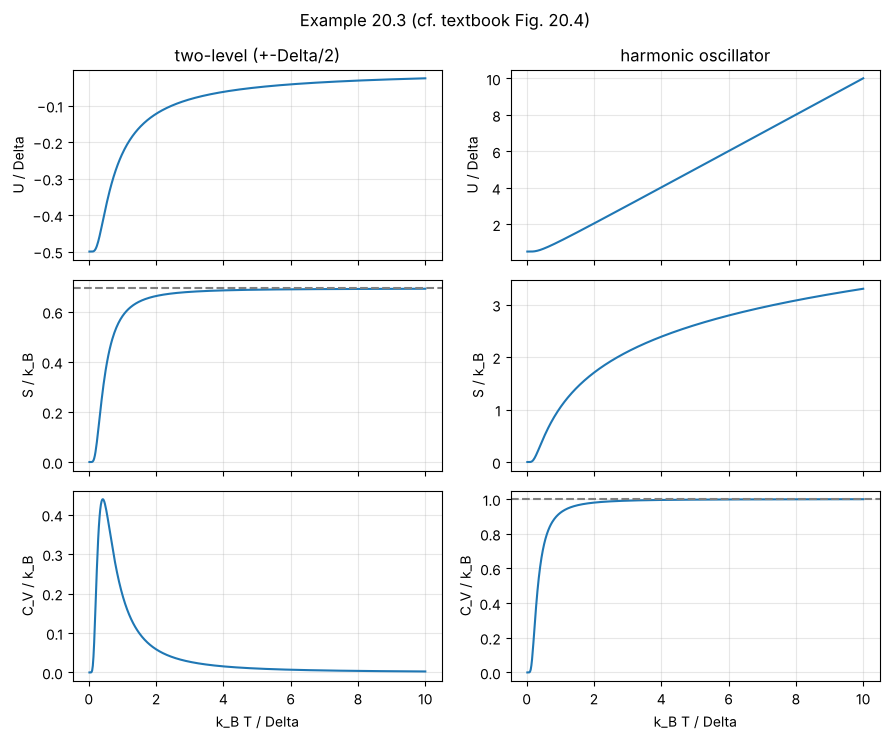

In [4]:
ts = np.linspace(0.02, 10, 500)
two = np.array([thermo(*levels('two', t), t) for t in ts])
sho = np.array([thermo(*levels('sho', t), t) for t in ts])
x = 1 / (2 * ts)        # beta*Delta/2 (2준위계)
y = 1 / ts              # beta*hbar*omega (조화진동자)
err = {
  'two U (20.24)': np.max(abs(two[:, 1] - (-0.5 * np.tanh(x)))),
  'two C (20.25)': np.max(abs(two[:, 3] - x**2 / np.cosh(x)**2)),
  'two S (20.27)': np.max(abs(two[:, 2] - (-x * np.tanh(x) + np.log(2 * np.cosh(x))))),
  'sho U (20.29)': np.max(abs(sho[:, 1] - (0.5 + 1 / np.expm1(y)))),
  'sho C (20.30)': np.max(abs(sho[:, 3] - y**2 * np.exp(y) / np.expm1(y)**2)),
  'sho S (20.32)': np.max(abs(sho[:, 2] - (y / np.expm1(y) - np.log(-np.expm1(-y))))),
}
for k, v in err.items(): print(f'max |sum - closed form| for {k}: {v:.1e}')

# 수치미분으로 C = dU/dT 확인
hh = 1e-5
dU = np.array([(thermo(*levels('two', t + hh), t + hh)[1] - thermo(*levels('two', t - hh), t - hh)[1]) / (2 * hh) for t in ts])
print(f'two-level: max |dU/dT - beta^2 var| = {np.max(abs(dU - two[:, 3])):.1e}')

# 쇼트키 봉우리
res = optimize.minimize_scalar(lambda t: -thermo(*levels('two', t), t)[3], bounds=(0.1, 2), method='bounded')
print(f'Schottky peak: k_BT/Delta = {res.x:.4f}, C_V/k_B = {-res.fun:.4f}')
print(f'limits (two-level): S(t=10) = {two[-1,2]:.4f} -> ln2 = {np.log(2):.4f};  U(t=0.02) = {two[0,1]:.4f}')
print(f'limits (SHO): C(t=10) = {sho[-1,3]:.4f} -> 1;  U(t=0.02) = {sho[0,1]:.4f} -> 1/2')

fig, ax = plt.subplots(3, 2, figsize=(9, 7.5), sharex=True)
for j, (d, name) in enumerate([(two, 'two-level (+-Delta/2)'), (sho, 'harmonic oscillator')]):
    for i, (col, lab) in enumerate([(1, 'U / Delta'), (2, 'S / k_B'), (3, 'C_V / k_B')]):
        ax[i, j].plot(ts, d[:, col]); ax[i, j].set_ylabel(lab)
    ax[0, j].set_title(name); ax[2, j].set_xlabel('k_B T / Delta')
ax[1, 0].axhline(np.log(2), ls='--', c='gray'); ax[2, 1].axhline(1, ls='--', c='gray')
fig.suptitle('Example 20.3 (cf. textbook Fig. 20.4)'); plt.tight_layout(); plt.show()

**해석.** 준위를 직접 더한 계산이 교재의 닫힌 식과 $10^{-14}$ 수준으로 일치한다.
2준위계는 고온에서 $S\to k_B\ln2$로 포화하고 $C_V$는 $k_BT/\Delta\approx0.42$에서 최대 0.44인 쇼트키 봉우리를 가진다. 조화진동자는 $C_V\to k_B$로 등분배 결과를 회복하고, $T\to0$에서 $U\to\tfrac12\hbar\omega$(영점에너지)이다.

## 예제 20.4 — 분배함수의 곱 (교재 295–296쪽)

**문제 요약.** 서로 독립인 두 부분계의 에너지가 $E_{i,j}=E^{(a)}_i+E^{(b)}_j$이면 $Z=Z_aZ_b$ (20.37)이다. 이원자 분자의 $Z=Z_{\rm vib}Z_{\rm rot}$ (20.39)가 그 예이다.

**풀이 아이디어.** 조화진동자(진동)와 회전자의 모든 조합 상태를 이중으로 더한 $Z$와 $Z_{\rm vib}Z_{\rm rot}$를 비교하고, $\ln Z$와 $C$가 더해짐을 확인한다. 진동 간격 $\hbar\omega=50\Delta_{\rm rot}$ (임의).

In [5]:
hw = 50.0                                    # 진동 간격 (회전 Delta 단위, 임의)
for t in (2.0, 20.0, 80.0):
    Ev, gv = levels('sho', t / hw); Ev = Ev * hw
    Er, gr = levels('rot', t)
    E2 = (Ev[:, None] + Er[None, :]).ravel(); g2 = (gv[:, None] * gr[None, :]).ravel()
    lnZ, U, S, C = thermo(E2, g2, t)
    lv = thermo(Ev, gv, t); lr = thermo(Er, gr, t)
    print(f't = {t:5.1f}: lnZ (double sum) = {lnZ:.10f}, lnZ_vib + lnZ_rot = {lv[0] + lr[0]:.10f};  '
          f'C = {C:.6f}, C_vib + C_rot = {lv[3] + lr[3]:.6f}')

t =   2.0: lnZ (double sum) = -11.6369679010, lnZ_vib + lnZ_rot = -11.6369679010;  C = 1.009052, C_vib + C_rot = 1.009052
t =  20.0: lnZ (double sum) = 1.8480775611, lnZ_vib + lnZ_rot = 1.8480775611;  C = 1.608948, C_vib + C_rot = 1.608948
t =  80.0: lnZ (double sum) = 4.8399752864, lnZ_vib + lnZ_rot = 4.8399752864;  C = 1.968077, C_vib + C_rot = 1.968077


**해석.** 이중 합과 곱의 결과가 소수점 10자리까지 같다. 분배함수가 곱이면 $\ln Z$와 그로부터 나오는 $U$, $S$, $C$가 모두 부분계의 합이 된다. 21장의 이원자 기체 열용량(데모 7)이 이 성질을 쓴다.

## 예제 20.5 — 스핀-½ 상자성체 (교재 296–298쪽, 그림 20.6)

**문제 요약.** 스핀 $N$개의 상자성체에서 $Z_1=2\cosh(\beta\mu_BB)$ (20.41), $Z_N=Z_1^N$ (20.42), 자기모멘트 $m=N\mu_B\tanh(\beta\mu_BB)$ (20.44)를 구하고, 약한 장에서 큐리 법칙 $\chi\propto1/T$ (20.48)를 얻는다.

**풀이 아이디어.** (1) $N=10$개 스핀의 $2^{10}$개 상태를 모두 더해 $Z_N=Z_1^N$과 $m$을 확인한다. (2) $m=-\partial F/\partial B$를 수치미분으로 구한다. (3) 그림 20.6을 다시 그린다.

Z_N (2^10 states) = 1.7814382968e+03,  Z_1^N = 1.7814382968e+03
m (direct) / (N muB) = 0.3237736094,  tanh(beta muB B) = 0.3237736094
-dF/dB / (N muB) = 0.3237736092


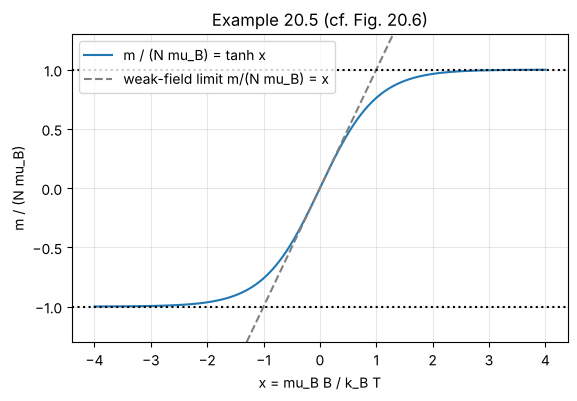

T =    1 K:  chi * T (reduced) = 1.000000  (Curie law: 1)
T =   10 K:  chi * T (reduced) = 1.000000  (Curie law: 1)
T =  100 K:  chi * T (reduced) = 1.000000  (Curie law: 1)
T =  300 K:  chi * T (reduced) = 1.000000  (Curie law: 1)


In [6]:
from itertools import product
N, B, T = 10, 1.0, 2.0                       # 스핀 수, 자기장 [T], 온도 [K]
beta = 1 / (kB * T)
# 모멘트가 B 방향이면 에너지 -muB*B (s = +1), 반대면 +muB*B (s = -1)
states = np.array(list(product([1, -1], repeat=N)))
E = -muB * B * states.sum(axis=1)
w = np.exp(-beta * (E - E.min()))
Z_N = w.sum() * np.exp(-beta * E.min())
Z1 = 2 * np.cosh(beta * muB * B)
m_direct = (w * muB * states.sum(axis=1)).sum() / w.sum()
print(f'Z_N (2^{N} states) = {Z_N:.10e},  Z_1^N = {Z1**N:.10e}')
print(f'm (direct) / (N muB) = {m_direct / (N * muB):.10f},  tanh(beta muB B) = {np.tanh(beta * muB * B):.10f}')

# m = -dF/dB,  F = -N k_B T ln(2 cosh(beta muB B))   (20.43)
F = lambda B: -N * kB * T * np.log(2 * np.cosh(muB * B / (kB * T)))
dB = 1e-6
print(f'-dF/dB / (N muB) = {-(F(B + dB) - F(B - dB)) / (2 * dB) / (N * muB):.10f}')

x = np.linspace(-4, 4, 400)
plt.plot(x, np.tanh(x), label='m / (N mu_B) = tanh x')
plt.plot(x, x, '--', c='gray', label='weak-field limit m/(N mu_B) = x')
plt.axhline(1, ls=':', c='k'); plt.axhline(-1, ls=':', c='k'); plt.ylim(-1.3, 1.3)
plt.xlabel('x = mu_B B / k_B T'); plt.ylabel('m / (N mu_B)'); plt.legend(); plt.title('Example 20.5 (cf. Fig. 20.6)'); plt.show()

# 큐리 법칙: chi*T 가 약한 장에서 일정 (n = N/V 는 소거되도록 chi / (n mu0 muB^2 / k_B) 로 본다)
for T in (1, 10, 100, 300):
    x0 = muB * 1e-3 / (kB * T)                 # B = 1 mT (약한 장)
    chi_red = np.tanh(x0) * kB / (muB * 1e-3)   # chi / (n mu0 muB^2/k_B),  chi = mu0 M / B,  M = n muB tanh x  → 단위 1/K
    print(f'T = {T:4d} K:  chi * T (reduced) = {chi_red * T:.6f}  (Curie law: 1)')

**해석.** $2^{10}$개 상태를 모두 더한 값이 $Z_1^N$과 같고, 평균 모멘트도 $\tanh(\beta\mu_BB)$와 정확히 같다. $-\partial F/\partial B$로도 같은 값이 나온다.
약한 장에서는 $\chi T$가 온도와 무관하게 일정하므로 큐리 법칙 $\chi\propto1/T$가 성립한다. 강한 장(큰 $x$)에서는 $m$이 $N\mu_B$에서 포화한다.

## 추가 문제 — 연습문제 20.8: 수소 원자의 분배함수 (교재 300쪽)

**문제 요약.** 수소 원자의 준위 $E_n=-R/n^2$ ($R=13.6$ eV, 축퇴도 $2n^2$)에서 $Z=\sum_n2n^2e^{R/n^2k_BT}$ (20.59)를 쓰고, $T\neq0$에서 이 합이 발산함을 보인 뒤 $n=1,2$만 남긴 근사 (20.60)로 300 K의 평균 에너지를 구한다. 교재에 수치 답은 없다.

**풀이 아이디어.** 부분합이 $n_{\max}$에 따라 계속 커지는 것을 보이고, $n=1,2$ 근사에서 $U=-\partial\ln Z/\partial\beta$를 계산한다.

beta R = R / k_B T = 526.1  →  ground-state term 2 e^(beta R) = 10^228.8
n_max =        1: ln Z = 526.764635
n_max =        2: ln Z = 526.764635
n_max =       10: ln Z = 526.764635
n_max =     1000: ln Z = 526.764635


n_max =  1000000: ln Z = 526.764635
tail (2/3) n_max^3 exceeds 2 e^(beta R) when n_max ~ 10^76.3  → the sum diverges, but only for absurdly large n


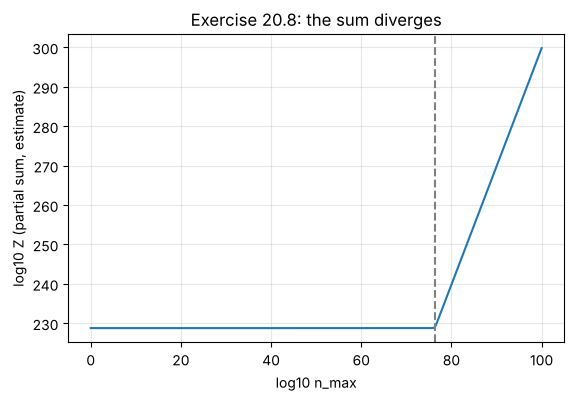

with n = 1, 2 only: P(n=2) = 1.777e-171,  U = -13.600000 eV  (ground state = -13.6 eV)


In [7]:
Ry = 13.6 * e                      # [J] (교재 값 13.6 eV)
T = 300.0; b = 1 / (kB * T)
print(f'beta R = R / k_B T = {b * Ry:.1f}  →  ground-state term 2 e^(beta R) = 10^{(np.log(2) + b * Ry) / np.log(10):.1f}')

# 부분합 ln Z(n_max) — 매우 큰 수이므로 로그로 계산 (logsumexp)
from scipy.special import logsumexp
def lnZ_partial(nmax):
    n = np.arange(1, int(nmax) + 1)
    return logsumexp(np.log(2 * n**2) + b * Ry / n**2)
for nmax in (1, 2, 10, 10**3, 10**6):
    print(f'n_max = {nmax:>8d}: ln Z = {lnZ_partial(nmax):.6f}')
# 큰 n 의 꼬리: sum 2n^2 ≈ (2/3) n_max^3  →  바닥상태 항을 넘는 n_max
log10_nstar = (b * Ry + np.log(3)) / (3 * np.log(10))
print(f'tail (2/3) n_max^3 exceeds 2 e^(beta R) when n_max ~ 10^{log10_nstar:.1f}  → the sum diverges, but only for absurdly large n')

L = np.linspace(0, 100, 400)                         # log10 n_max
lnZ_est = np.logaddexp(np.log(2) + b * Ry, np.log(2 / 3) + 3 * L * np.log(10))
plt.plot(L, lnZ_est / np.log(10))
plt.axvline(log10_nstar, ls='--', c='gray')
plt.xlabel('log10 n_max'); plt.ylabel('log10 Z (partial sum, estimate)'); plt.title('Exercise 20.8: the sum diverges'); plt.show()

# n = 1, 2 만 남긴 근사 (식 20.60)
E = np.array([-Ry, -Ry / 4]); g = np.array([2, 8])
P = g * np.exp(-b * (E - E.min())); P /= P.sum()
U = (P * E).sum()
print(f'with n = 1, 2 only: P(n=2) = {P[1]:.3e},  U = {U / e:.6f} eV  (ground state = {-13.6:.1f} eV)')

**해석.** 높은 준위의 항은 $2n^2e^{R/n^2k_BT}\to2n^2$으로 줄지 않으므로 부분합은 $n_{\max}^3$처럼 끝없이 커진다(발산). 다만 300 K에서 꼬리가 바닥상태 항을 넘으려면 $n_{\max}\sim10^{76}$이 필요하다. 실제 원자는 유한한 부피 안에 있어 그런 상태가 존재하지 않는다.
$n=1,2$만 남기면 300 K에서 $n=2$의 확률은 $10^{-170}$ 정도로 사실상 0이고, 평균 에너지는 바닥상태 에너지 $-13.6$ eV와 같다.